# RGB and Grayscale Inputs for Cell Counting

This experiment compares RGB images with three-channel grayscale images using YOLO26n.
Both arms estimate total cell count, combining Live and Dead annotations into one Cell class.
The dataset contains 500 source images and uses the team's frozen 351/74/75 train/validation/test split.

The implementation follows the team's [YOLO notebook](https://github.com/Erdos-Projects/fall-2026-automated-cell-counting/blob/main/notebooks/03_cell_counting.ipynb), with a fixed split, a matched RGB control, and count-based evaluation.

## Environment


In [1]:
from pathlib import Path
import sys, os, json, shutil, time, hashlib, subprocess
from datetime import datetime, timezone
import importlib.metadata
import torch

if not torch.cuda.is_available():
    raise RuntimeError('A CUDA GPU is required for this experiment.')
print(json.dumps({'python': sys.version.split()[0], 'torch': torch.__version__,
                  'gpu': torch.cuda.get_device_name(0)}, indent=2))


{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "gpu": "Tesla T4"
}


In [2]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'roboflow==1.7.1', 'ultralytics==8.4.183', 'albumentations==2.0.8'], check=True)
os.environ['NO_ALBUMENTATIONS_UPDATE'] = '1'
import albumentations as A
from roboflow import Roboflow
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
for package, expected in {'roboflow': '1.7.1', 'ultralytics': '8.4.183', 'albumentations': '2.0.8'}.items():
    actual = importlib.metadata.version(package)
    if actual != expected:
        raise RuntimeError(f'Unexpected dependency version: {package} {actual}')
print('Pinned training dependencies verified.')


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Pinned training dependencies verified.


## Persistent storage

Verify persistent output storage before downloading or preparing experiment data.


In [3]:
from google.colab import drive
drive.mount('/content/drive', timeout_ms=300000)
DRIVE_ROOT = Path('/content/drive/MyDrive')
if not DRIVE_ROOT.is_dir():
    raise RuntimeError('Google Drive is not mounted; stop before data preparation or training.')
print('Persistent Google Drive storage is available.')


Mounted at /content/drive
Persistent Google Drive storage is available.


## Data access

The Roboflow credential is read at runtime from a Colab secret or a hidden input prompt.
The source is Version 1 of `ruiping-huang/cell-counting-zeqo5-ncyud`, exported in YOLO26 format.


In [4]:
from getpass import getpass
api_key = None
try:
    from google.colab import userdata
    api_key = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    pass
if not api_key:
    api_key = getpass('Roboflow API key: ').strip()
if not api_key:
    raise ValueError('An API key is required.')
rf = Roboflow(api_key=api_key)
del api_key


In [5]:
ROBOFLOW_WORKSPACE = 'ruiping-huang'
ROBOFLOW_PROJECT = 'cell-counting-zeqo5-ncyud'
ROBOFLOW_VERSION = 1
dataset = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT).version(ROBOFLOW_VERSION).download('yolo26')
EXPORT_ROOT = Path(dataset.location).resolve()
if not (EXPORT_ROOT / 'data.yaml').is_file():
    raise FileNotFoundError('The downloaded export does not contain data.yaml.')


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cell-counting-1 in yolo26:: 100%|██████████| 1004/1004 [00:00<00:00, 9636.19it/s]


## Frozen split and annotation checks

Images are matched to the frozen manifest by unique original filename. Annotation counts are checked for every image.
All boxes are retained and their classes are merged into Cell. RGB images are saved as lossless PNG files without resizing.
The manifest is pinned to a repository commit. Identity and count agreement do not establish pixel or box-coordinate equality with an unavailable team export.


In [6]:
"""Align a Roboflow YOLO export to the team's frozen image-level manifest."""
from pathlib import Path
import hashlib
import json
import math
import re
import pandas as pd
from PIL import Image


def original_image_key(name):
    return re.sub(r"_(?:jpe?g|png|tiff?)\.rf\..*$", "", name, flags=re.IGNORECASE)


def yolo_label_path(image):
    parts = list(Path(image).parts)
    if "images" not in parts:
        raise ValueError(f"Expected an images directory: {image}")
    parts[len(parts)-1-parts[::-1].index("images")] = "labels"
    return Path(*parts).with_suffix(".txt")


def prepare_frozen_yolo(export_root, manifest_path, output_root):
    export_root, manifest_path, output_root = map(Path, (export_root, manifest_path, output_root))
    manifest = pd.read_csv(manifest_path)
    if not {"uid", "file_name", "count", "split"}.issubset(manifest.columns):
        raise ValueError("The frozen manifest is missing required columns")
    if len(manifest) != 500 or manifest.split.value_counts().to_dict() != {"train":351,"test":75,"valid":74}:
        raise ValueError("Expected the frozen 351/74/75 split")
    manifest["original_key"] = manifest.file_name.map(original_image_key)
    if not manifest.uid.is_unique or not manifest.original_key.is_unique:
        raise ValueError("Ambiguous identities in the frozen manifest")
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    images = sorted(p for p in export_root.rglob("*") if p.is_file() and p.suffix.lower() in extensions and p.parent.name == "images")
    lookup = {}
    for p in images:
        key = original_image_key(p.name)
        if key in lookup:
            raise ValueError("Duplicate originals or augmented copies found; expected 500 unique originals")
        lookup[key] = p
    if len(images) != 500 or set(lookup) != set(manifest.original_key):
        raise ValueError("Downloaded images do not match the team's 500 originals")
    checked = []
    for row in manifest.itertuples():
        image = lookup[row.original_key]
        label = yolo_label_path(image)
        if not label.is_file():
            raise FileNotFoundError(label)
        lines = [s.split() for s in label.read_text().splitlines() if s.strip()]
        if len(lines) != row.count:
            raise ValueError(f"Count mismatch for {row.original_key}: {len(lines)} vs {row.count}")
        normalized = []
        for fields in lines:
            if len(fields) != 5:
                raise ValueError(f"Expected detection box labels, not polygons: {label}")
            category, cx, cy, w, h = map(float, fields)
            if not all(math.isfinite(v) for v in (category,cx,cy,w,h)) or not category.is_integer() or category < 0:
                raise ValueError(f"Invalid class or coordinate in {label}")
            if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < w <= 1 and 0 < h <= 1):
                raise ValueError(f"Invalid normalized box in {label}")
            normalized.append(f"0 {cx:.8f} {cy:.8f} {w:.8f} {h:.8f}")
        with Image.open(image) as im:
            if im.size != (640,640):
                raise ValueError(f"Expected 640x640 source images, found {im.size}: {image}")
        checked.append((row,image,normalized))
    marker = output_root / "alignment_metadata.json"
    signature = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
    if output_root.exists() and any(output_root.iterdir()) and not marker.exists():
        raise FileExistsError("Output contains an unfinished/unknown dataset. Preserve it and choose a new directory.")
    if marker.exists() and json.loads(marker.read_text())["manifest_sha256"] != signature:
        raise ValueError("Existing output uses a different split")
    inventory = []
    for row,image,lines in checked:
        images_dir = output_root / row.split / "images"
        labels_dir = output_root / row.split / "labels"
        images_dir.mkdir(parents=True,exist_ok=True)
        labels_dir.mkdir(parents=True,exist_ok=True)
        stem = row.uid.replace("/","_")
        target = images_dir / f"{stem}.png"
        with Image.open(image) as im:
            rgb = im.convert("RGB")
            rgb.save(target)
            pixel_hash = hashlib.sha256(rgb.tobytes()).hexdigest()
        (labels_dir/f"{stem}.txt").write_text("\n".join(lines))
        inventory.append(dict(uid=row.uid,original_key=row.original_key,source_file=str(image),
                              split=row.split,count=row.count,path=str(target.resolve()),
                              decoded_rgb_sha256=pixel_hash))
    config = output_root / "data.yaml"
    config.write_text(f"path: {output_root.resolve()}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames:\n  0: Cell\n")
    pd.DataFrame(inventory).to_csv(output_root/"image_alignment.csv",index=False)
    meta = dict(manifest_sha256=signature,n_images=500,n_boxes=sum(r.count for r,_,_ in checked),
                split_counts=manifest.split.value_counts().to_dict(),classes=["Cell"],
                identity_check="Unique original filename plus exact annotation count per image",
                geometry_caveat="No pixel/coordinate equality claim against an unavailable team raw export")
    marker.write_text(json.dumps(meta,ensure_ascii=False,indent=2))
    print(json.dumps(meta,ensure_ascii=False,indent=2))
    return config


In [7]:
import urllib.request
FROZEN_COMMIT = 'b646a2eadb6ea4419e87c8f65b4c108d437a8861'
MANIFEST_URL = f'https://raw.githubusercontent.com/Erdos-Projects/fall-2026-automated-cell-counting/{FROZEN_COMMIT}/splits/splits.csv'
MANIFEST = Path('/content/ruiping_frozen_splits.csv')
urllib.request.urlretrieve(MANIFEST_URL, MANIFEST)
EXPECTED_MANIFEST_SHA256 = 'b6f0cae5b41154d5d4b35239e662667260393ac8c01bfb909d7e252fd3fdfeb0'
if hashlib.sha256(MANIFEST.read_bytes()).hexdigest() != EXPECTED_MANIFEST_SHA256:
    raise ValueError('The downloaded frozen manifest does not match the pinned file hash.')
RGB_ROOT = EXPORT_ROOT.with_name(EXPORT_ROOT.name + '_ruiping_frozen_rgb')
RGB_YAML = prepare_frozen_yolo(EXPORT_ROOT, MANIFEST, RGB_ROOT)
data_info = check_det_dataset(str(RGB_YAML), autodownload=False)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
split_paths = {s: Path(data_info[s]).resolve() for s in ('train', 'val', 'test')}
split_files = {s: sorted(p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS)
               for s, root in split_paths.items()}
split_counts = {s: len(paths) for s, paths in split_files.items()}
if split_counts != {'train': 351, 'val': 74, 'test': 75}:
    raise ValueError(f'Unexpected split counts: {split_counts}')
print(json.dumps(split_counts, indent=2))


{
  "manifest_sha256": "b6f0cae5b41154d5d4b35239e662667260393ac8c01bfb909d7e252fd3fdfeb0",
  "n_images": 500,
  "n_boxes": 26715,
  "split_counts": {
    "train": 351,
    "test": 75,
    "valid": 74
  },
  "classes": [
    "Cell"
  ],
  "identity_check": "Unique original filename plus exact annotation count per image",
  "geometry_caveat": "No pixel/coordinate equality claim against an unavailable team raw export"
}
{
  "train": 351,
  "val": 74,
  "test": 75
}


## Grayscale preprocessing

Grayscale conversion retains luminance and replicates it across three channels.
It is applied to training, validation, and test images. Geometry and labels are unchanged.
The preview uses training images only.


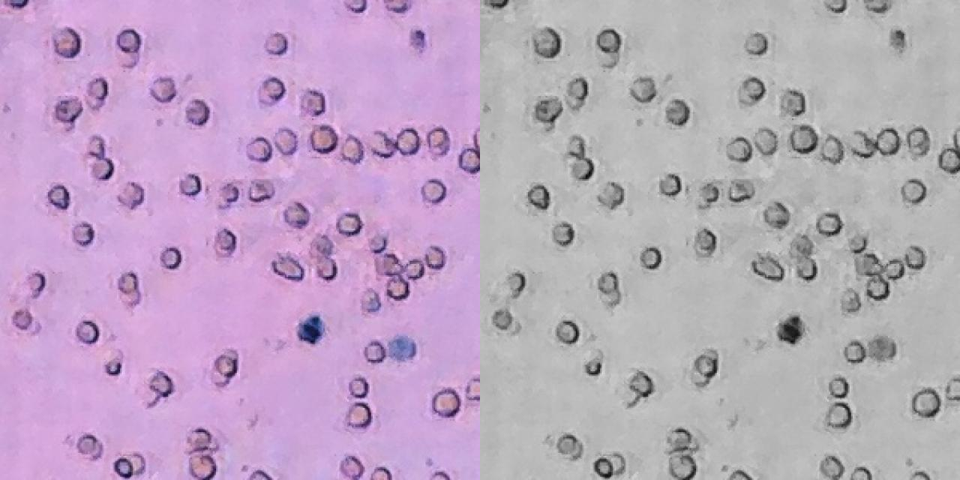

RGB (left); grayscale (right). Paired image and label checks passed.


In [8]:
GRAY_ROOT = RGB_ROOT.with_name(RGB_ROOT.name + '_grayscale')
GRAY_ROOT.mkdir(exist_ok=True)
for original in sorted(RGB_ROOT.rglob('*')):
    if not original.is_file() or original.suffix.lower() == '.cache':
        continue
    target = GRAY_ROOT / original.relative_to(RGB_ROOT)
    target.parent.mkdir(parents=True, exist_ok=True)
    if original.suffix.lower() in IMAGE_EXTS:
        with Image.open(original) as image:
            ImageOps.grayscale(image.convert('RGB')).convert('RGB').save(target.with_suffix('.png'))
    elif original.name != 'data.yaml':
        shutil.copyfile(original, target)
gray_config = {'path': str(GRAY_ROOT), 'names': data_info['names']}
for split, directory in split_paths.items():
    gray_config[split] = str(GRAY_ROOT / directory.relative_to(RGB_ROOT))
GRAY_YAML = GRAY_ROOT / 'data.yaml'
GRAY_YAML.write_text(yaml.safe_dump(gray_config, sort_keys=False))
check_det_dataset(str(GRAY_YAML), autodownload=False)
for paths in split_files.values():
    for rgb_path in paths:
        gray_path = (GRAY_ROOT / rgb_path.relative_to(RGB_ROOT)).with_suffix('.png')
        if yolo_label_path(rgb_path).read_bytes() != yolo_label_path(gray_path).read_bytes():
            raise ValueError(f'Label mismatch: {rgb_path.name}')
        with Image.open(gray_path) as image:
            pixels = np.asarray(image)
        if pixels.ndim != 3 or pixels.shape[2] != 3 or not (
                np.array_equal(pixels[..., 0], pixels[..., 1]) and np.array_equal(pixels[..., 1], pixels[..., 2])):
            raise ValueError(f'Invalid three-channel grayscale image: {gray_path.name}')
sample = split_files['train'][0]
with Image.open(sample) as image:
    rgb = image.convert('RGB')
    gray = ImageOps.grayscale(rgb).convert('RGB')
    preview = Image.new('RGB', (rgb.width * 2, rgb.height))
    preview.paste(rgb, (0, 0))
    preview.paste(gray, (rgb.width, 0))
display(preview.resize((960, 480)))
print('RGB (left); grayscale (right). Paired image and label checks passed.')


## Experiment configuration and provenance

Both arms start independently from the same pretrained checkpoint. Shared settings are seed 0, batch size 16,
640-pixel inputs, at most 100 epochs, and early stopping patience 20.
Training augmentation consists only of horizontal and vertical flips (each probability 0.5) and a uniformly sampled
0/90/180/270-degree rotation. All other random augmentation is disabled, including optional library defaults.
Bounding boxes follow the image transforms. Validation and test preprocessing is deterministic.

Run metadata, data checks, actual training arguments, checkpoint hashes, and stage events are saved with the results.


In [9]:
RUN_ID = 'rgb_grayscale_seed0_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUTPUT = Path('/content/drive/MyDrive/ruiping_cell_counting') / RUN_ID
OUTPUT.mkdir(parents=True, exist_ok=False)
TRAIN_SETTINGS = dict(epochs=100, imgsz=640, single_cls=True, seed=0, batch=16, device=0,
                      plots=True, deterministic=True, patience=20, workers=2,
                      hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, bgr=0.0,
                      fliplr=0.5, flipud=0.5, translate=0.0, scale=0.0,
                      degrees=0.0, shear=0.0, perspective=0.0,
                      mosaic=0.0, close_mosaic=0, mixup=0.0, cutmix=0.0, copy_paste=0.0,
                      augmentations=[A.to_dict(A.RandomRotate90(p=1.0))])
# Custom transforms replace the optional Albumentations defaults.
# Native degrees=90 would sample continuous angles and is intentionally not used.
metadata = dict(run_id=RUN_ID, status='prepared',
                source=dict(workspace=ROBOFLOW_WORKSPACE, project=ROBOFLOW_PROJECT,
                            version=ROBOFLOW_VERSION, export_format='yolo26'),
                frozen_manifest_commit=FROZEN_COMMIT,
                manifest_sha256=hashlib.sha256(MANIFEST.read_bytes()).hexdigest(),
                split_counts=split_counts, classes=['Cell'], training=TRAIN_SETTINGS,
                grayscale='PIL luminance conversion replicated across three channels',
                gpu=torch.cuda.get_device_name(0), python=sys.version,
                versions={p: importlib.metadata.version(p) for p in
                          ['torch', 'ultralytics', 'roboflow', 'albumentations', 'numpy', 'pandas', 'Pillow']},
                completed_arms=[])
def save_metadata():
    (OUTPUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2, default=str))
def record_event(event, **details):
    entry = dict(timestamp_utc=datetime.now(timezone.utc).isoformat(), event=event, details=details)
    with (OUTPUT / 'events.jsonl').open('a') as handle:
        handle.write(json.dumps(entry, default=str) + '\n')
    print(f'[{entry["timestamp_utc"]}] {event}')
save_metadata()
shutil.copyfile(MANIFEST, OUTPUT / 'splits.csv')
for name in ['alignment_metadata.json', 'image_alignment.csv']:
    shutil.copyfile(RGB_ROOT / name, OUTPUT / name)
record_event('data_checks_passed', split_counts=split_counts)
record_event('paired_preprocessing_checks_passed', n_images=500)
print('Run directory:', OUTPUT)


[2026-10-26T04:01:57.470137+00:00] data_checks_passed
[2026-10-26T04:01:57.475468+00:00] paired_preprocessing_checks_passed
Run directory: /content/drive/MyDrive/ruiping_cell_counting/rgb_grayscale_seed0_20261026T040157Z


In [10]:
def verify_orientation_transforms():
    from ultralytics.data.augment import Albumentations, RandomFlip
    from ultralytics.utils.instance import Instances
    image = np.arange(16 * 16 * 3, dtype=np.uint16).reshape(16, 16, 3).astype(np.uint8)
    box = np.array([[0.25, 0.375, 0.125, 0.25]], dtype=np.float32)
    def labels():
        return dict(img=image.copy(), cls=np.array([[0]], dtype=np.float32),
                    instances=Instances(box.copy(), np.zeros((0, 1000, 2), dtype=np.float32),
                                        bbox_format='xywh', normalized=True))
    rotation = Albumentations(p=1.0, transforms=TRAIN_SETTINGS['augmentations'])
    if rotation.transform is None:
        raise RuntimeError('Required rotation transform could not be initialized.')
    expected_boxes = [box.copy()]
    for _ in range(3):
        cx, cy, width, height = expected_boxes[-1][0]
        expected_boxes.append(np.array([[cy, 1 - cx, height, width]], dtype=np.float32))
    seen = set()
    for _ in range(64):
        output = rotation(labels())
        matches = [k for k in range(4) if np.array_equal(output['img'], np.rot90(image, k))]
        if len(matches) != 1:
            raise RuntimeError('Rotation changed pixels beyond a right-angle permutation.')
        k = matches[0]
        if len(output['cls']) != 1 or not np.allclose(output['instances'].bboxes, expected_boxes[k], atol=1e-6):
            raise RuntimeError('Rotation did not preserve the bounding box.')
        seen.add(k)
    if seen != set(range(4)):
        raise RuntimeError('Rotation preflight did not observe all four orientations.')
    for direction, axis, coordinate in [('horizontal', 1, 0), ('vertical', 0, 1)]:
        output = RandomFlip(p=1.0, direction=direction)(labels())
        expected = box.copy()
        expected[:, coordinate] = 1 - expected[:, coordinate]
        if not np.array_equal(output['img'], np.flip(image, axis)) or not np.allclose(
                output['instances'].bboxes, expected, atol=1e-6):
            raise RuntimeError(f'Image/box flip check failed: {direction}')
    record_event('orientation_geometry_checks_passed', rotation_samples=64,
                 orientations=[0, 90, 180, 270], forced_flip_checks=2)

verify_orientation_transforms()


albumentations: RandomRotate90(p=1.0)
[2026-10-26T04:01:57.642315+00:00] orientation_geometry_checks_passed


In [11]:
def train_arm(variant, data_yaml):
    arm_dir = OUTPUT / variant
    if arm_dir.exists():
        raise FileExistsError(f'Existing run directory: {arm_dir}')
    model = YOLO('yolo26n.pt')
    def log_augmentation_pipeline(trainer):
        from ultralytics.data.augment import Albumentations
        def walk(transform):
            yield transform
            for child in getattr(transform, 'transforms', []):
                yield from walk(child)
        wrappers = [t for t in walk(trainer.train_loader.dataset.transforms)
                    if isinstance(t, Albumentations)]
        if len(wrappers) != 1 or wrappers[0].transform is None:
            raise RuntimeError('The required orientation augmentation was not initialized.')
        active = wrappers[0].transform.transforms
        if len(active) != 1 or not isinstance(active[0], A.RandomRotate90) or active[0].p != 1.0:
            raise RuntimeError('Unexpected Albumentations pipeline; training stopped.')
        for argument in ('hsv_h', 'hsv_s', 'hsv_v', 'bgr', 'fliplr', 'flipud', 'translate',
                         'scale', 'degrees', 'shear', 'perspective', 'mosaic', 'close_mosaic',
                         'mixup', 'cutmix', 'copy_paste'):
            if getattr(trainer.args, argument) != TRAIN_SETTINGS[argument]:
                raise RuntimeError(f'Training setting changed: {argument}')
        record_event('augmentation_pipeline_initialized', variant=variant,
                     transforms=str(trainer.train_loader.dataset.transforms))
    model.add_callback('on_train_start', log_augmentation_pipeline)
    initial_path = Path(model.ckpt_path)
    initial_hash = hashlib.sha256(initial_path.read_bytes()).hexdigest()
    if 'initial_weights_sha256' in metadata and metadata['initial_weights_sha256'] != initial_hash:
        raise ValueError('The two arms have different initial checkpoint hashes.')
    metadata['initial_weights_sha256'] = initial_hash
    metadata['status'] = f'training_{variant}'
    save_metadata()
    record_event('training_started', variant=variant, settings=TRAIN_SETTINGS)
    try:
        result = model.train(data=str(data_yaml), project=str(OUTPUT), name=variant, **TRAIN_SETTINGS)
        weights = Path(result.save_dir) / 'weights/best.pt'
        if not weights.is_file() or Path(result.save_dir).resolve() != arm_dir.resolve():
            raise RuntimeError('Unexpected training output directory or missing checkpoint.')
        actual = dict(weights_sha256=hashlib.sha256(weights.read_bytes()).hexdigest(),
                      actual_args=vars(model.trainer.args))
        (arm_dir / 'training_record.json').write_text(json.dumps(actual, indent=2, default=str))
        metadata['completed_arms'].append(variant)
        metadata['status'] = 'trained' if len(metadata['completed_arms']) == 2 else f'{variant}_trained'
        save_metadata()
        record_event('training_completed', variant=variant, weights_sha256=actual['weights_sha256'])
    except Exception as error:
        metadata['status'] = f'{variant}_failed'
        save_metadata()
        record_event('training_failed', variant=variant, error_type=type(error).__name__)
        raise
    return weights


## RGB control


In [12]:
rgb_weights = train_arm('rgb', RGB_YAML)


[2026-10-26T04:01:58.348717+00:00] training_started
New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomRotate90', 'p': 1.0}}], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cell-counting-1_ruiping_frozen_rgb/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=N

## Grayscale arm


In [13]:
gray_weights = train_arm('grayscale', GRAY_YAML)


[2026-10-26T04:17:50.320048+00:00] training_started
New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomRotate90', 'p': 1.0}}], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cell-counting-1_ruiping_frozen_rgb_grayscale/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0

## Validation threshold selection and test evaluation

Each arm's confidence threshold minimizes count MAE on the 74 validation images. Both arms are then evaluated on
the same 75 test images. The primary endpoint is total-count MAE; secondary endpoints are RMSE, R-squared, bias,
the fraction of counts within 10% of the reference, and runtime. Detection mAP is not count accuracy.
Test results are not used to revise this experiment's settings.


In [14]:
def reference_count(image):
    label = yolo_label_path(image)
    if not label.is_file():
        raise FileNotFoundError(label)
    return sum(bool(line.strip()) for line in label.read_text().splitlines())

def count_metrics(reference, prediction):
    reference, prediction = np.asarray(reference), np.asarray(prediction)
    error = prediction - reference
    denominator = ((reference - reference.mean()) ** 2).sum()
    return dict(mae=float(np.abs(error).mean()), rmse=float(np.sqrt((error ** 2).mean())),
                r2=float(1 - (error ** 2).sum() / denominator) if denominator else None,
                within_10pct=float((np.abs(error) <= .1 * reference).mean()), bias=float(error.mean()))

if set(metadata['completed_arms']) != {'rgb', 'grayscale'}:
    raise RuntimeError('Both training arms must finish before test evaluation.')
if (OUTPUT / 'count_comparison.csv').exists():
    raise FileExistsError('Test evaluation already exists. Read the saved results.')
comparison_rows = []
for variant, root in [('rgb', RGB_ROOT), ('grayscale', GRAY_ROOT)]:
    net = YOLO(str(OUTPUT / variant / 'weights/best.pt'))
    files = {s: [p if variant == 'rgb' else (root / p.relative_to(RGB_ROOT)).with_suffix('.png')
                 for p in split_files[s]] for s in ['val', 'test']}
    validation = net.predict([str(p) for p in files['val']], conf=.01, max_det=1000,
                             imgsz=640, batch=16, verbose=False, device=0)
    reference_val = [reference_count(p) for p in files['val']]
    grid = np.round(np.arange(.01, .91, .01), 2)
    tuning = pd.DataFrame([dict(confidence=float(t), **count_metrics(reference_val,
              [int((r.boxes.conf.cpu().numpy() >= t).sum()) for r in validation])) for t in grid])
    tuning.to_csv(OUTPUT / variant / 'validation_count_thresholds.csv', index=False)
    threshold = float(tuning.loc[tuning.mae.idxmin(), 'confidence'])
    (OUTPUT / variant / 'selected_threshold.json').write_text(json.dumps(
        dict(confidence=threshold, selection_set='validation', n_images=74), indent=2))
    record_event('threshold_selected', variant=variant, confidence=threshold)
    torch.cuda.synchronize()
    started = time.perf_counter()
    predictions = net.predict([str(p) for p in files['test']], conf=.01, max_det=1000,
                              imgsz=640, batch=16, verbose=False, device=0)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    reference = [reference_count(p) for p in files['test']]
    predicted = [int((r.boxes.conf.cpu().numpy() >= threshold).sum()) for r in predictions]
    counts = pd.DataFrame(dict(file_name=[p.stem for p in files['test']],
                               reference_count=reference, predicted_count=predicted))
    counts['error'] = counts.predicted_count - counts.reference_count
    counts.to_csv(OUTPUT / variant / 'test_counts.csv', index=False)
    comparison_rows.append(dict(variant=variant, confidence=threshold, n_test=len(reference),
                               **count_metrics(reference, predicted), seconds_per_image=elapsed/len(reference)))
    record_event('test_evaluation_completed', variant=variant, n_images=len(reference))
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(OUTPUT / 'count_comparison.csv', index=False)
metadata['status'] = 'evaluated'
metadata['timing_scope'] = 'Image loading, preprocessing, inference, and postprocessing; model loading and offline grayscale conversion excluded. Validation inference precedes timing.'
save_metadata()
display(comparison)


[2026-10-26T04:23:33.778346+00:00] threshold_selected
[2026-10-26T04:23:35.457052+00:00] test_evaluation_completed
[2026-10-26T04:23:37.981336+00:00] threshold_selected
[2026-10-26T04:23:39.401635+00:00] test_evaluation_completed


,variant,confidence,n_test,mae,rmse,r2,within_10pct,bias,seconds_per_image
0,rgb,0.44,75,1.173333,1.591645,0.988453,1.000000,0.080000,0.022090
1,grayscale,0.33,75,1.586667,2.247962,0.976967,0.946667,-0.013333,0.018612


## Count diagnostics

The comparison is conditional on one training seed and the frozen random split. Leave-one-session-out evaluation
and repeated seeds are needed before making broader claims about generalization or training variability.
Historical Cellpose results should be compared only after checking data and evaluation compatibility; timing across
different devices and measurement scopes is not a controlled speed comparison.


rgb: largest count errors


,file_name,reference_count,predicted_count,error,absolute_error
18,train_177,65,61,-4,4
26,train_207,44,48,4,4
69,valid_67,58,54,-4,4
20,train_19,67,64,-3,3
24,train_20,55,58,3,3
32,train_232,32,35,3,3


grayscale: largest count errors


,file_name,reference_count,predicted_count,error,absolute_error
18,train_177,65,56,-9,9
66,valid_14,54,60,6,6
26,train_207,44,49,5,5
39,train_258,67,62,-5,5
27,train_21,63,59,-4,4
32,train_232,32,36,4,4


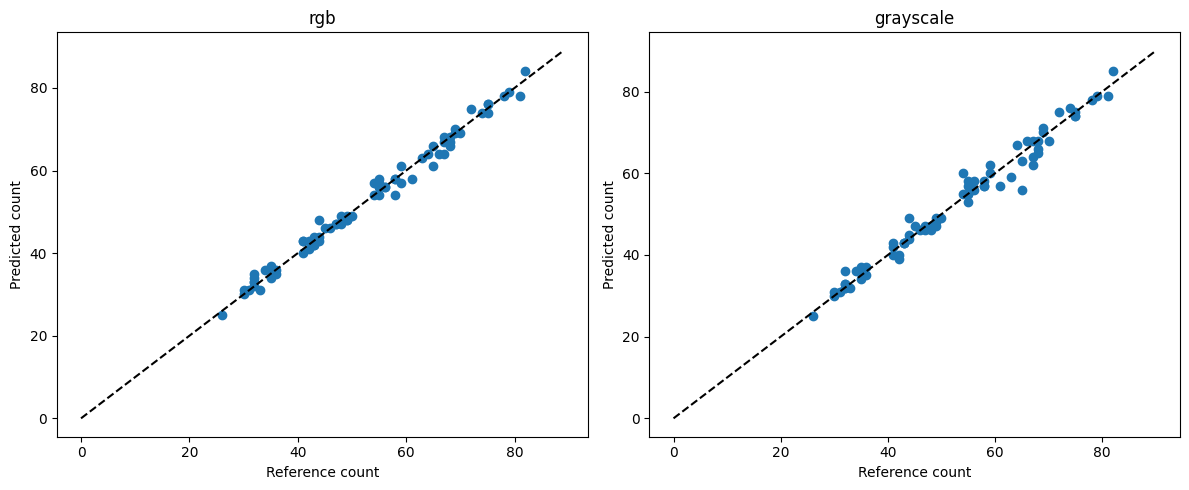

[2026-10-26T04:23:40.090857+00:00] diagnostics_saved


In [15]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(comparison), figsize=(6 * len(comparison), 5), squeeze=False)
for axis, variant in zip(axes.flat, comparison.variant):
    counts = pd.read_csv(OUTPUT / variant / 'test_counts.csv')
    axis.scatter(counts.reference_count, counts.predicted_count)
    limit = max(counts.reference_count.max(), counts.predicted_count.max()) + 5
    axis.plot([0, limit], [0, limit], 'k--')
    axis.set(title=variant, xlabel='Reference count', ylabel='Predicted count')
    worst = counts.assign(absolute_error=counts.error.abs()).nlargest(6, 'absolute_error')
    worst.to_csv(OUTPUT / variant / 'largest_count_errors.csv', index=False)
    print(f'{variant}: largest count errors')
    display(worst)
fig.tight_layout()
fig.savefig(OUTPUT / 'predicted_vs_reference.png', dpi=160)
plt.show()
record_event('diagnostics_saved')


## Artifact export

Create a file inventory with SHA256 hashes and a standalone archive of this completed run.


In [16]:
if metadata['status'] != 'evaluated':
    raise RuntimeError('Evaluation must finish before exporting the completed run.')
ARCHIVE = Path('/content') / (RUN_ID + '.zip')
if ARCHIVE.exists():
    raise FileExistsError(f'An artifact archive already exists: {ARCHIVE}')
record_event('artifact_export_started')
metadata['status'] = 'complete'
save_metadata()
inventory = []
for artifact in sorted(OUTPUT.rglob('*')):
    if artifact.is_file() and artifact.name != 'artifact_manifest.json':
        inventory.append(dict(path=str(artifact.relative_to(OUTPUT)),
                              bytes=artifact.stat().st_size,
                              sha256=hashlib.sha256(artifact.read_bytes()).hexdigest()))
(OUTPUT / 'artifact_manifest.json').write_text(json.dumps(inventory, indent=2))
shutil.make_archive(str(ARCHIVE.with_suffix('')), 'zip', root_dir=OUTPUT)
archive_hash = hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
ARCHIVE.with_suffix('.zip.sha256').write_text(f'{archive_hash}  {ARCHIVE.name}\n')
print('Artifact archive:', ARCHIVE)
print('Archive SHA256:', archive_hash)
print('Archived files:', len(inventory) + 1)


[2026-10-26T04:25:38.298847+00:00] artifact_export_started
Artifact archive: /content/rgb_grayscale_seed0_20261026T040157Z.zip
Archive SHA256: f9a97aa5329f3c48fe6df34566277854e8f926058f792e07c780d67b998b75df
Archived files: 60
